c:\Users\abdel\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 2.00G/2.00G [10:10<00:00, 3.27MB/s]


 100% |███████████████| 5717/5717 [33.0s elapsed, 0s remaining, 162.9 samples/s]      
Dataset info written to 'C:\Users\abdel\fiftyone\voc-2012\info.json'
Loading 'voc-2012' split 'train'
 100% |███████████████| 5717/5717 [12.4s elapsed, 0s remaining, 322.5 samples/s]      
Dataset 'voc-2012-train' created
Computing metadata...
 100% |███████████████| 5717/5717 [1.5s elapsed, 0s remaining, 4.2K samples/s]         
Name:        voc-2012-train
Media type:  image
Num samples: 5717
Persistent:  False
Tags:        []
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    ground_truth:     fiftyone.core.fields.Embedde

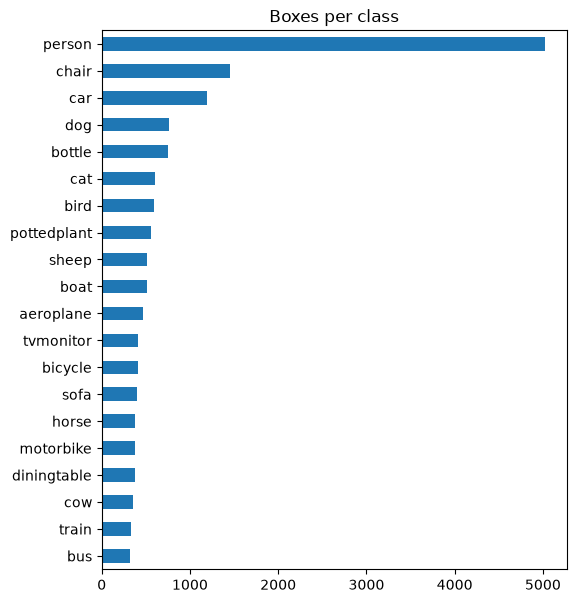

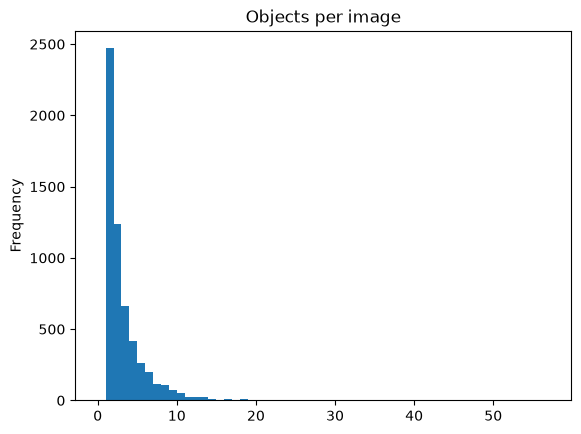

count    5717.000000
mean        2.759139
std         2.789480
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        56.000000
dtype: float64
w    h  
500  375    2403
     333     744
375  500     487
333  500     176
500  334     134
Name: count, dtype: int64


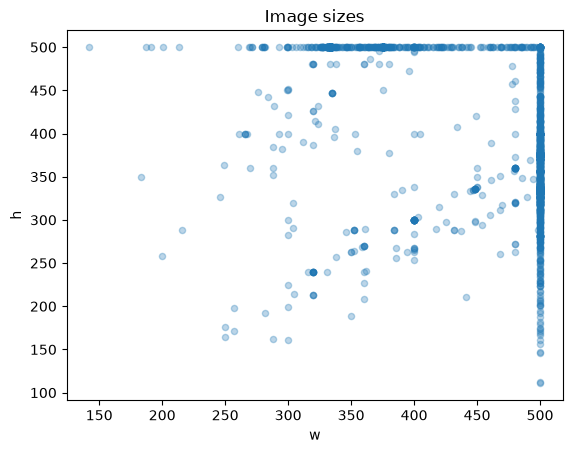

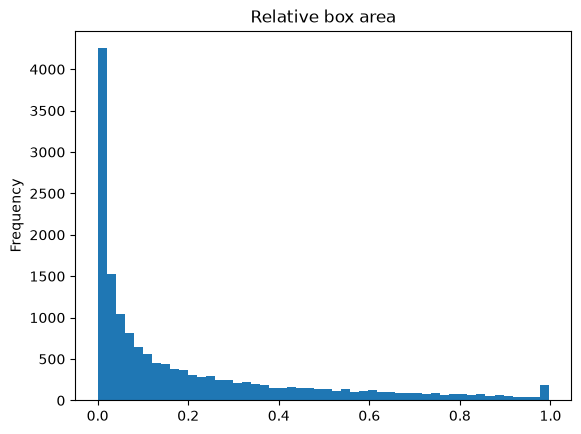

count    15774.000000
mean         0.200321
std          0.248780
min          0.000187
25%          0.017340
50%          0.086933
75%          0.295968
max          0.996004
dtype: float64
small (<1%): 0.1800431089134018


In [1]:
import fiftyone as fo
import fiftyone.zoo as foz
from fiftyone import ViewField as F
import pandas as pd
import matplotlib.pyplot as plt

dataset = foz.load_zoo_dataset("voc-2012", split="train")  
dataset.compute_metadata()  

print(dataset)                        
print(dataset.first())                 
print("images:", len(dataset))
print("boxes:", dataset.count("ground_truth.detections"))

counts = pd.Series(dataset.count_values("ground_truth.detections.label")).sort_values()
counts.plot.barh(figsize=(6, 7), title="Boxes per class")
plt.show()

per_img = pd.Series(dataset.values(F("ground_truth.detections").length()))
per_img.plot.hist(bins=range(0, per_img.max() + 2), title="Objects per image")
plt.show()
print(per_img.describe())

sizes = pd.DataFrame({
    "w": dataset.values("metadata.width"),
    "h": dataset.values("metadata.height"),
})
print(sizes.value_counts().head())     
sizes.plot.scatter(x="w", y="h", alpha=0.3, title="Image sizes")
plt.show()

boxes = dataset.values("ground_truth.detections.bounding_box")
areas = pd.Series([b[2] * b[3] for img in boxes for b in img])
areas.plot.hist(bins=50, title="Relative box area")
plt.show()
print(areas.describe())
print("small (<1%):", (areas < 0.01).mean())

fo.close_app()
session = fo.launch_app(dataset)